---
title: Scaling Decision Analysis with Hyperbolic Trade Space Identification
abstract: |
  A trade study must produce an answer and a justification an accountable executive can follow.
  Principal component analysis (PCA) is trusted as reproducible and interpretable, but explains
  variance, not what trades against what. We explain tensions. A fitted generalized posynomial
  reference surface, a model of the table, not the Pareto boundary, gives the table a coordinate system. A reversible chart separates where a design sits along the surface from its energy
  differential, its level relative to the surface; each facet reports its contending metrics, an
  n-lemma (by analogy with dilemma and trilemma) with exchange rates. Fitting one facet is a
  geometric program, solved as a convex program after a logarithmic change of variables; fitting
  several alternates assigning designs to facets with one such program per facet;
  descent is derived, stationarity checked numerically, local optimality derived under stated
  hypotheses. The method belongs beside PCA, and the two chain. On one case it scales where
  dominance does not: the nondominated set stops shortlisting with more metrics. On a cubesat
  model coupling power, mass and attitude control, with ten attributes under two
  controller-gain regimes, one facet reports one tension and three facets
  three different contending sets. Derived statements point to script and proof.
---

In [1]:
import paper_paths  # puts the repository and examples/adcs on sys.path

paper_paths.inline_figures()

In [2]:
import case

study = case.load_study("primary")

In [3]:
fits = case.k_fits(study)

(sect-problem)=
## The decision problem

A decision analysis has two products: an answer, and a justification that an accountable executive can follow and defend. Decision analysis seeks responsible choice among conflicting objectives [@keeney1993decisions] and clear conversation with the decision-maker [@howard1988decision]. The justification is the hard product: the process turning much data into little must be recognized, reproducible and rigorous.

In the practice we know, a trade study is a document: a grid, a table, a ranking by weighted criteria; surveys compare them [@baker2012survey]. The weights are human judgments, susceptible to bias in trade studies [@smith2007ameliorating; @chilli2026decision]. Systems engineering is moving from document-based [@henderson2021value] to model-based practice [@madni2018model], but the computational alternatives we meet are bespoke and opaque. To displace it, a method must handle real data's scale, complexity and noise interpretably.

PCA reduces dimensionality and increases interpretability while minimizing information loss [@jolliffe2016principal]. But variance says where the data are free and nothing about trade-offs, which a decision-maker must know to defend a judgment call.

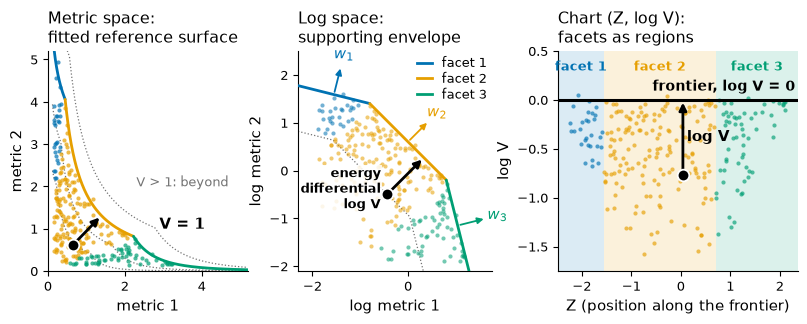

In [4]:
from figures.figure1 import figure1

figure1()

:::{figure} figures/figure1.png
:label: fig-trade-space
Left: the fitted reference surface. Middle: the supporting envelope, with each facet's normal. Right: the chart, where the surface is one line and the facets are regions along the position Z. The black arrow is the same step in each pane: one design's energy differential. [enlarge](figures/figure1.png)
:::

We take PCA as inspiration and explain tensions where it explains variance ({numref}`Figure %s <fig-trade-space>`). Two objectives may be aligned in one region and opposed in another. A posynomial surface fitted to the table gives it a coordinate system; the surface models the table and is not the Pareto boundary ({prf:ref}`def-objects`). Each facet names the metrics that contend on it and their exchange rates: an n-lemma (by analogy with dilemma and trilemma). The method sits beside PCA and the two chain: {ref}`Appendix D.16 <sub-d-16>` reads the principal directions of the near-frontier chart as the trade-offs the sampling exercised, a reading and not a result.

**Contribution.** Scaling up trade studies with a reproducible computational method that has a PCA-like feel. On this case, with the number of designs and of metrics, dominance stops shortlisting: its nondominated set nears the whole table.

In [5]:
from generate_findings import nondominated_sentence

nondominated_sentence(study)

'Of 706 feasible cubesat designs, the nondominated sets hold 7 to 8 on 2, 145 to 146 on 4 and 671 on 10 attributes (a range is the spread over five regenerations of the data under rounding-level perturbation, <a href="supporting-material/#sub-d-11" target="_self" style="color:inherit;text-decoration:underline">Appendix D.11</a>).'

**Main results** ({numref}`Section %s <sect-results>`; each has hypotheses, a sketch and a script).

1. The fitted reference surface is the unit level set of a degree-one weighted geometric mean, not the Pareto boundary ({prf:ref}`thm-invariant`).
2. The one-facet fit is a geometric program, convex in the logarithmic variables ({prf:ref}`thm-kkt`, {prf:ref}`thm-convex`); its exponents are exchange rates and its chart is reversible ({prf:ref}`thm-elasticity`, {prf:ref}`thm-chart`).
3. The posynomial extension reduces to the one-facet fit, and a maximizer of V is Pareto-efficient ({prf:ref}`thm-extension`, {prf:ref}`thm-pareto`).
4. The multi-facet algorithm has three levels of guarantee and a stopping declaration ({prf:ref}`thm-descent`, {prf:ref}`lem-gap`, {prf:ref}`lem-margin`, {prf:ref}`prop-local`).
5. Numerical: the status a fit reaches. Open: Q1 to Q4 and the search's monotonicity.
6. On a cubesat model coupling power, mass and attitude control the facets separate contending sets that one facet blends ({numref}`Section %s <sect-case-analysis>`).

**Organization.** Appendices: {ref}`A <appendix-a>` notation, {ref}`B <appendix-b>` proofs, {ref}`C <appendix-c>` model, {ref}`D <appendix-d>` results, {ref}`E <appendix-e>` assumptions, {ref}`F <appendix-f>` reproducibility, {ref}`G <appendix-g>` prior art.

(sect-prior-art)=
## Prior art, by family

We claim no priority. {numref}`Table %s <tab-families-1>` says what each family produces, what we share, how we differ and where to read it. {ref}`Appendix G <appendix-g>` is the larger register; it is not exhaustive and says for every entry what this work does differently, extends or adds.

In [6]:
from generate_prior_art import family_table

family_table()

Family and sources,Produces,Shares,Differs
Pareto and multiobjective optimizationMiettinen 1999; Ehrgott 2005; Zitzler and Thiele 1999; Deb et al. 2002,Returns a nondominated set of designs,the weights act as a trade-off,Returns no coordinate system and no exponents
Data envelopment analysis (DEA)Charnes et al. 1978; Banker et al. 1984; Andersen and Petersen 1993; Färe et al. 1994; Allen et al. 1997; Dyson et al. 2001,Evaluates the relative efficiency of each decision-making unit,"A one-sided envelope of the data, a score per unit",One exponent vector per facet
Production and distance functionsCobb and Douglas 1928; Shephard 1970; Färe and Primont 1995; Farrell 1957,"The Cobb-Douglas production form, and the Shephard distance function",the constant-returns Cobb-Douglas form,Attributes in place of inputs
Deterministic and stochastic frontiersAigner and Chu 1968; Afriat 1972; Richmond 1974; Greene 1980; Aigner et al. 1977; Battese 1992,Estimates frontier production functions,A one-sided criterion on log-linear residuals,A smooth soft maximum over a simplex-constrained geometric mean
Principal component analysis (PCA)Jolliffe and Cadima 2016,Finds uncorrelated components that successively maximize variance,an unsupervised summary in a few directions,"The criterion is a one-sided soft maximum, not variance"
Compositional and log-ratio PCAAitchison 1983; Aitchison 1986; Egozcue et al. 2003,PCA of compositional data,an isometric logratio chart,"The criterion is one-sided, and the weights lie on the simplex"
Geometric programming and max-affine fittingBoyd et al. 2007; Hoburg and Abbeel 2014; Hoburg et al. 2016; Magnani and Boyd 2009; Candès et al. 2008,Geometric programming with generalized posynomials,"The model class, the K > 1 refit scheme","this method fits an envelope, the one-sided boundary of the data"
Kernel and hyperbolic PCASchölkopf et al. 1998; Chami et al. 2021,PCA in an implicit feature space,the feature-engineering kin of the kernel direction,"""Hyperbolic"" here means the level surfaces of V in metric space"
Tradespace explorationRoss et al. 2004; Ross and Hastings 2005; Ross et al. 2010; Stump et al. 2009; Spero et al. 2014,Value-focused broad exploration of design alternatives,"The setting, a table of evaluated designs",this method fits and reports a coordinate system and a score
Decision analysis and multiple-criteria methodsHoward 1988; Keeney and Raiffa 1993; Baker and Whalen 2012; Parnell 2016,Decision analysis with a normative versus descriptive distinction,The weights are trade-off rates,"The weights are fitted from the data's edge, not elicited"


::::{table} The families of prior art closest to this work: what each produces, what it shares with this work, how this work differs, and the sources.
:label: tab-families-1
:::{embed} #tab-families
:remove-input: true
:::
::::

[@miettinen1999nonlinear; @ehrgott2005multicriteria; @zitzler1999multiobjective; @deb2002fast; @charnes1978measuring; @banker1984some; @andersen1993procedure; @fare1994productivity; @allen1997weights; @dyson2001pitfalls; @cobb1928theory; @shephard1970theory; @fare1995multi; @farrell1957measurement; @aigner1968estimating; @afriat1972efficiency; @richmond1974estimating; @greene1980maximum; @aigner1977formulation; @battese1992frontier; @jolliffe2016principal; @aitchison1983principal; @aitchison1986statistical; @egozcue2003isometric; @boyd2007tutorial; @hoburg2014geometric; @hoburg2016data; @magnani2009convex; @candes2008enhancing; @schoelkopf1998nonlinear; @chami2021horopca; @foellmer2026entropic; @ahmadijavid2012entropic; @ross2004multi; @ross2005tradespace; @ross2010revisiting; @stump2009visual; @spero2014tradespace; @howard1988decision; @keeney1993decisions; @baker2012survey; @parnell2016trade; @hirshorn2017nasa; @chilli2026decision; @smith2007ameliorating; @parnell2021system; @madni2018model; @henderson2021value]

**Pareto methods.** Pareto methods return a nondominated set and find its members by scalarization, for example the weighting method [@miettinen1999nonlinear; @ehrgott2005multicriteria]; evolutionary algorithms generate such sets [@zitzler1999multiobjective; @deb2002fast]. A nondominated set says which designs survive. The fit says what trades against what. Dominance is a hard comparison that stops discriminating, on this case, as metrics are added ({numref}`Section %s <sect-problem>` counts it), while the fit returns an exponent vector per facet, a band of near-frontier designs and an effective sample size. The two meet in one result: a maximizer of V with positive exponents is Pareto-efficient ({prf:ref}`thm-pareto`). **Open.** Which part of the Pareto boundary the facets reach is our reading: the theorem gives efficiency of a maximizer, not the converse.

**Data envelopment analysis.** DEA is the closer cousin [@charnes1978measuring; @banker1984some]. It scores each unit against the data by mathematical programming, with weights obtained from the data rather than set in advance [@banker1984some]; a super-efficiency variant ranks efficient units against a reference technology spanned by all other units [@andersen1993procedure], and Malmquist indices run across data sets [@fare1994productivity]. We differ in what the envelope is. We fit one exponent vector per facet, a global named structure, where DEA obtains weights unit by unit, and practice has added weights restrictions [@allen1997weights] and protocols for applying it [@dyson2001pitfalls]. Our facets are piecewise log-linear with constant elasticities within a facet. Our metrics are larger-is-better with homogeneity from the simplex, in place of inputs, outputs and a choice of returns to scale. Our boundary is a soft maximum with a temperature, a band and an effective sample size, not a boundary set by extreme units. We solve one convex program and K refits, and return coordinates with a pull-back to attribute units.

**Lineage.** The weighted geometric mean with exponents summing to one has the constant-returns Cobb-Douglas form [@cobb1928theory], and reading V as the factor that scales a design to the boundary is our distance-function reading, after Shephard's characterization of a technology by its distance function [@shephard1970theory; @fare1995multi; @farrell1957measurement]. Frontier estimation by programming, corrected least squares and one-sided error is the family of one-sided fits, reviewed in [@battese1992frontier] after [@aigner1968estimating; @afriat1972efficiency; @aigner1977formulation]. The chart is in the spirit of log-ratio coordinates for compositional data [@aitchison1983principal; @egozcue2003isometric]. The model class and refit scheme come from geometric programming and max-affine fitting [@boyd2007tutorial; @hoburg2016data; @magnani2009convex]; the soft maximum is an entropic risk functional [@foellmer2026entropic]. Kernel PCA is the feature-engineering kin of the direction in {numref}`Section %s <sect-discussion>` [@schoelkopf1998nonlinear], and "hyperbolic" here is unrelated to hyperbolic PCA [@chami2021horopca]. Tradespace exploration lets an analyst explore designs [@ross2005tradespace; @stump2009visual]; we fit it. Combining these pieces in one estimator is our design. We did not find the combination in the sources reviewed, which {ref}`Appendix G <appendix-g>` lists.

(sect-notation)=
## Preliminaries and notation

We assume multivariate calculus, linear algebra and convex optimization. Mathematical notation follows Boyd and Vandenberghe [@boyd2004convex] and estimator terms follow the scikit-learn documentation [@pedregosa2011scikit; @buitinck2013api]; {ref}`Appendix A <appendix-a>` is the full register of symbols and terms.

**The pipeline.** A configuration $c$ (the design variables) is evaluated into attributes $a$ (the evaluation outcomes), which the analyst conditions into metrics $m$: strictly positive and larger is better. Stage 1 evaluates, and **the evaluation is a black box to the method: a simulator behind a system model, a physical test, or a human assessment.** The cubesat model of {numref}`Section %s <sect-case-construction>` is one instance behind that abstraction, not part of the method, so the method stays relevant as tools move or where scoring comes from physical systems or human judgment. Stage 2 is conditioning, the analyst's step, done with scikit-learn tools ({numref}`Section %s <sect-methods>`). Stages 3 and 4, identification and analysis, are the method. With $N$ designs and $d$ metrics, $M\in\mathbb{R}^{N\times d}_{>0}$ is the table of metrics, $U=\log M$ has rows $u_i$, and $\Delta$ is the probability simplex in $\mathbb{R}^d$.

**Assumptions.** A1: metrics are strictly positive. A2: exponents lie on the simplex. A3: $\tau>0$. A4: conditioning is log-affine and invertible. A5: noise, where used, is Gaussian in log space. A6: $\kappa>0$ and each term's exponents lie on the simplex. A7: the chart's basis is orthonormal and sums to zero. {numref}`Section %s <sect-methods>` adds the regularity conditions R1 and R2.

**Map and territory.** All models are wrong, some are useful, and a model is useful for a specific purpose in a specific situation; here the purpose is improving trade studies. The formal results are properties of mathematical objects, conditioned on assumptions that we cannot certify for a given table of designs, and the implementation approximates those objects numerically. Results are read in light of the gaps ledger in {ref}`Appendix E <appendix-e>`, which records for each place where the map and the territory part the assumption that bridges it, what cannot be proved, the evidence on sensitivity and what that means for reading the result.

**Words.** A term, a monomial and a facet are one object: the term of the posynomial, the product of powers, the flat piece in log space. We say facet for the geometry and term for the algebra. Three objects carry the word frontier ({prf:ref}`def-objects`).

(sect-definitions)=
## Definitions

:::{prf:definition} Invariant form
:label: def-invariant
For $w\in\Delta$, $V(m)=\prod_j m_j^{w_j}$ and, with a fitted offset $\beta$, $\log V=w\cdot u-\beta$.
:::

:::{prf:definition} Posynomial
:label: def-posynomial
$V_K(m)=\big(\sum_{k=1}^{K}c_k\prod_j m_j^{\kappa w_{kj}}\big)^{1/\kappa}$ with $w_k\in\Delta$, $c_k=e^{-\kappa\beta_k}$, and $\Phi_K(u)=\frac1\kappa\log\sum_k e^{\kappa(w_k\cdot u-\beta_k)}$ its logarithm.
:::

:::{prf:definition} Temperatures and band
:label: def-temperature
The fit temperature $\tau>0$ sets how hard the maximum is ($\tau=\infty$ is exact); the term temperature $\kappa>0$ how sharply facets meet. The near-frontier band is $|\log V|<1/\tau$: in the soft maximum a design inside it weighs within a factor $e$ of one on the surface.
:::

:::{prf:definition} The chart
:label: def-chart
$Z=Bu$, with $BB^\top=I$ and $B\mathbf 1=0$, is the position along the frontier, free of overall scale. $(Z,\log V)$ is the chart, a reversible rewriting of the metrics; $\log V$ is the energy differential (level offset): the level of a potential relative to the reference surface, negative inside, positive beyond.
:::

:::{prf:definition} The n-lemma
:label: def-nlemma
The contending set of facet $k$ is the support (exponents above $10^{-9}$) of the exact-maximum ($\tau=\infty$) fit to the facet's rows; its size $n_k$ names it. It is found, not assumed. Working-temperature exponents grade the members, and a member can carry a small one.
:::

:::{prf:definition} Reach and share
:label: def-reach
The reach $\beta_k$ is the support value of the data in direction $w_k$. The facet share is the fraction of near-frontier designs assigned to facet $k$; it shows which facets carry most of the frontier and depends on the band.
:::

:::{prf:definition} Exchange rate
:label: def-exchange
Along facet $k$, $\mathrm{d}\log m_j/\mathrm{d}\log m_i=-w_{ki}/w_{kj}$, the percent change of $j$ per percent change of $i$.
:::

:::{prf:definition} Ascent direction
:label: def-ascent
On facet $k$ the tangent space $\{v:w_k\cdot v=0\}$ trades contending metrics at constant $V$; the normal $w_k$ is the steepest ascent of $\log V$.
:::

:::{prf:definition} Three objects
:label: def-objects
The fitted reference surface is $V=1$ at finite $\tau$; some designs lie beyond it. The supporting envelope is the $\tau=\infty$ fit, which none exceeds. The Pareto boundary is the nondominated set of the attainable set, a property of the system.
:::

(sect-methods)=
## Methods

**Conditions of the theory.** Two regularity conditions carry interpretive weight. R1: the balanced point lies in the relative interior of a facet of the supporting envelope with positive normal; otherwise exponents are a subgradient choice, not an identified trade-off. R2: the assignment margin $\gamma=\min_i[s_{i,k(i)}-\max_{k\neq k(i)}s_{ik}]$ is positive, with $s_{ik}=w_k\cdot u_i-\beta_k$ the energy differential of design $i$ against facet $k$.

**The model.** At $K=1$ the frontier is the unit level set of $V$. The fit asks for the positive combination of log-metrics along which the data have the smallest upper extent, under an entropic soft maximum. With scores $s_i=w\cdot u_i$,
$$
J_\tau(w)=\tfrac1\tau\log\Big(\tfrac1N\sum_{i}e^{\tau w\cdot u_i}\Big),\quad w^*=\arg\min_{w\in\Delta}J_\tau(w),\quad\beta=J_\tau(w^*).
$$
$\beta$ is the log-mean-exp, never the unnormalized log-sum-exp: the factor $1/N$ makes it a property of the shape of the data, not the number of designs ({prf:ref}`thm-lme`). At $\tau=\infty$ the fit is a linear program. At finite $\tau$ one facet is a geometric program, convex after the change of variables $x=e^{w}$ [@boyd2007tutorial] ({ref}`Appendix B, L4.14 to L4.24 <appendix-b>`); the model is a generalized posynomial; several facets alternate assigning designs to facets with one such program per facet. $\tau$ puts a target fraction of designs above $V=1$: 10 percent here, a convention that keeps one extreme design from setting the surface (halving or doubling it leaves the contending sets unchanged, {ref}`Appendix D.5 <sub-d-5>`).

**Conditioning (stage 2).** The theory asks that conditioning be log-affine per metric, $\log m_j=\alpha_j\log(a_j+s_j)+b_j$ with $\alpha_j\neq0$. A negative $\alpha_j$ marks smaller-is-better; the shift $s_j$ places the origin; a scaler equalizes log-spread so one $\tau$ serves every metric. These choices define the question: rescaling one metric changes which facet is tangent. Zeros are tolerated in data and masked in the fit, negative values are rejected, and the pull-back to attribute units is exact ({prf:ref}`thm-pullback`). An exponent above the participation threshold ($10^{-3}$) participates; one at or below $10^{-12}$ is numerically zero, not mathematically so (membership: {prf:ref}`def-nlemma`).

**The estimator.** The fit is a scikit-learn transformer of the decomposition family: `fit` identifies exponents and offsets, `transform` returns the chart, `inverse_transform` reverses it, `score_samples` returns the energy differential. It has no `predict`: prediction composes a supervised regressor with the chart.

**Simplifying assumptions.** We name each where it is made, defend it, and say in {numref}`Section %s <sect-future>` how to go beyond it. (i) *One facet at $K=1$:* constant exchange rates; $K>1$ is built. (ii) *Hard assignment, smoothing on request:* facets are fitted at $\kappa=\infty$ with kinks on the ridges; a finite $\kappa$ moves the score by at most $(\log K)/\kappa$ ({prf:ref}`thm-extension`) and, by construction, leaves the facets unchanged. (iii) *The analyst chooses $K$:* a modelling choice, as the number of retained components is for PCA. (iv) *Small $K$:* the case needs three facets and a small $K$ keeps each contending set readable. (v) *Log-affine conditioning:* it is exactly invertible ({prf:ref}`thm-pullback`) and stays inside geometric programming. (vi) *A log-convex envelope:* $\Phi_K$ is convex in $u$, which keeps later optimization convex; no $K$ represents non-log-convex structure.

(sect-results)=
## Results

**Derived** means proved from its hypotheses by a plain-SymPy script that the tests run; **Numerical** means observed and not proved; **Open** means not established. Whether the hypotheses suit a table is a human judgment ({numref}`Section %s <sect-discussion>`).

### The fit and its geometry

:::{prf:theorem} Homogeneity and the invariant form (L1)
:label: thm-invariant
**Derived.** *Hypotheses.* A1 (metrics positive), A2 (exponents on the simplex).

For $k>0$: $V(km)=kV(m)$ and $V(m/V(m))=1$; $V(me^{-\beta})=e^{-\beta}V(m)$, so $\log V=w\cdot u-\beta$.
:::

:::{prf:proof} Sketch
A1 gives $V=\exp(w\cdot u)$; A2 turns scaling by $k$ into the addition of $\log k$.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_01_homogeneity.py`, `verify`; {ref}`Appendix B, L1 <appendix-b>`.
:::

:::{prf:proposition} Uniform shift (L2)
:label: prop-shift
**Derived.** *Hypotheses.* A1, A2, A3; $w\in\Delta$.

$J_\tau(w;U+c\mathbf 1^\top)=J_\tau(w;U)+c$: $\beta$ moves by $c$ and $w^*$ is unchanged.
:::

:::{prf:proof} Sketch
Weights summing to one shift every score by $c$, and the log-mean-exp is shift-equivariant.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_02_shift.py`, `verify`; {ref}`Appendix B, L2 <appendix-b>`.
:::

:::{prf:theorem} Gradient and the simplex KKT conditions (L3)
:label: thm-kkt
**Derived.** *Hypotheses.* A2; R1 for the facet-normal reading; $w$ minimizes $J_\tau$ on $\Delta$.

$\nabla J_\tau=U^\top p$, $p=\mathrm{softmax}(\tau Uw)$. With $g=\nabla J_\tau(w)$, $\lambda=w\cdot g$: $g_j\ge\lambda$ and $w_j(g_j-\lambda)=0$. Balanced hard-support geometry does not imply an interior minimizer at finite $\tau$.
:::

:::{prf:proof} Sketch
Differentiate the log-mean-exp. Active simplex constraints are affine with independent gradients (I10: first-order conditions).
:::

:::{admonition} Script
:class: tip
`derivation/lemma_03_gradient_kkt.py`, `verify`; {ref}`Appendix B, L3 <appendix-b>`.
:::

:::{prf:theorem} Convexity of the fit (L4)
:label: thm-convex
**Derived.** *Hypotheses.* A1, A3.

$\frac{d^2}{dt^2}J_\tau(w+tv)|_0=\tau\mathrm{Var}_p(v\cdot u)\ge0$: $J_\tau$ is convex, not claimed strictly.
:::

:::{prf:proof} Sketch
The curvature is $\tau$ times a $p$-weighted variance, nonnegative on every line (I11: convex on every line is convex).
:::

:::{admonition} Script
:class: tip
`derivation/lemma_04_convexity.py`, `verify`; {ref}`Appendix B, L4 <appendix-b>`.
:::

:::{prf:theorem} Log-mean-exp against log-sum-exp (L5)
:label: thm-lme
**Derived.** *Hypotheses.* A3; F5 (the maximum is attained).

$\mathrm{LSE}_\tau=\mathrm{LME}_\tau+(\log N)/\tau$; $\mathrm{mean}\le\mathrm{LME}_\tau\le\max_is_i$ and $\mathrm{LME}_\tau\ge\max_is_i-(\log N)/\tau$; the mean and the maximum are the limits.
:::

:::{prf:proof} Sketch
The identity is algebra; shifting by the maximum squeezes the sum between one and $N$ unit-size terms.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_05_lse_lme.py`, `verify`; {ref}`Appendix B, L5 <appendix-b>`.
:::

:::{prf:proposition} Gaussian cumulant (L6)
:label: prop-cumulant
**Derived.** *Hypotheses.* A2, A3, A5, I5 (moment generating functions multiply); a population identity, with no consistency claim.

$\frac1\tau\log\mathbb{E}\,e^{\tau w\cdot\varepsilon}=\tau\sigma^2\lVert w\rVert^2/2$.
:::

:::{prf:proof} Sketch
The moment generating function of an independent sum is the product of its factors.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_06_gaussian_cumulant.py`, `verify`; {ref}`Appendix B, L6 <appendix-b>`.
:::

:::{prf:theorem} Exchange rates and improvement factors (L7)
:label: thm-elasticity
**Derived.** *Hypotheses.* A1, A2; $w_j\neq0$; the frontier is the hyperplane $\{w\cdot u=\beta\}$.

On it $\mathrm{d}\log m_j/\mathrm{d}\log m_k=-w_k/w_j$. Improving metric $j$ alone by $V^{-1/w_j}$, or every metric by $1/V$, reaches $V=1$.
:::

:::{prf:proof} Sketch
A tangent $e_k+xe_j$ has derivative $w_k+xw_j$. Scaling $m_j$ by $f$ adds $w_j\log f$ to $\log V$. Identifying these rates with the fit needs {prf:ref}`thm-kkt` and R1.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_07_elasticities.py`, `verify`; {ref}`Appendix B, L7 <appendix-b>`.
:::

:::{prf:theorem} The chart (L8)
:label: thm-chart
**Derived.** *Hypotheses.* A7; I6 ($QQ^\top=I$ implies $Q^\top Q=I$).

$Z(u+c\mathbf 1)=Z(u)$ and $u=B^\top Z+\frac1d(\mathbf 1^\top u)\mathbf 1$: the map between $u$ and (position, log-scale) is a bijection, and $Q=[B;\mathbf 1^\top/\sqrt d]$ is orthogonal.
:::

:::{prf:proof} Sketch
$B\mathbf 1=0$ kills the shift; the blocks of $QQ^\top$ and I6 give the round trip.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_08_helmert_chart.py`, `verify`; {ref}`Appendix B, L8 <appendix-b>`.
:::

:::{prf:theorem} Pull-back to attributes (L9)
:label: thm-pullback
**Derived.** *Hypotheses.* A2, A4: $\log m_j=\alpha_j\log(a_j+s_j)+b_j$, $\alpha_j\neq0$.

$V=e^{w\cdot b-\beta}\prod_j(a_j+s_j)^{w_j\alpha_j}$, and conditioning is invertible; negative $w_j\alpha_j$ marks a cost attribute.
:::

:::{prf:proof} Sketch
Substitute the conditioning; the offset enters only through $\sum_jw_j=1$.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_09_pullback.py`, `verify`; {ref}`Appendix B, L9 <appendix-b>`.
:::

:::{prf:theorem} The posynomial extension (L10)
:label: thm-extension
**Derived.** *Hypotheses.* A1, A6; F10 (the maximum is attained) for the limit.

$\Phi_K(u+c\mathbf 1)=\Phi_K(u)+c$; $\Phi_1=w_1\cdot u-\beta_1$; $\max_kx_k\le\Phi_K\le\max_kx_k+(\log K)/\kappa$ with $x_k=w_k\cdot u-\beta_k$; $e^{\kappa\Phi_K}$ is a posynomial in $m$.
:::

:::{prf:proof} Sketch
Simplex exponents turn the shift into $c$ in every term; the bounds are the squeeze of {prf:ref}`thm-lme`; each term is a monomial (I4: log-sum-exp of affine functions is GP-compatible).
:::

:::{admonition} Script
:class: tip
`derivation/lemma_10_extension.py`, `verify`; {ref}`Appendix B, L10 <appendix-b>`.
:::

:::{prf:theorem} A maximizer of V is Pareto-efficient (L11)
:label: thm-pareto
**Derived.** *Hypotheses.* A2. The converse is not claimed.

A maximizer of $V$ is weakly efficient in all $d$ metrics, and efficient when every $w_j>0$; at $K>1$, $\kappa=\infty$, through an active term.
:::

:::{prf:proof} Sketch
For $u'=u+\delta$, $\delta\ge0$, the gain $\sum_jw_j\delta_j$ is a sum of nonnegative terms; take the contrapositive. That only the log-convex part of a front is reached by some $w$ is our statement, not a cited one.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_11_pareto.py`, `verify`; {ref}`Appendix B, L11 <appendix-b>`.
:::

### The algorithm for several facets

The assignment of designs to facets is combinatorial, so the fit of $K$ facets is not convex. The estimator adapts the partition-and-refit scheme of Magnani and Boyd [@magnani2009convex] to the one-sided entropic fit. With $n_k$ the rows of facet $k$ and $\bar u_k$ their mean log-metric,
$$
f_k(w)=J_\tau(Uw)-\bar u_k\cdot w,\qquad F(W)=\tfrac1N\sum_i\big(\beta_{k(i)}-w_{k(i)}\cdot u_i\big)=\sum_k\tfrac{n_k}{N}f_k(w_k),
$$
where $f_k$ is the facet refit, convex by {prf:ref}`thm-convex`, and $F$ the mean slack, the one-sided volume between cloud and envelope.

> **for each restart:** label rows by the nearest of $K$ random centres in the chart. **repeat:** (1) *refit* $w_k=\arg\min_{w\in\Delta}f_k(w)$ over all rows, $\beta_k=J_\tau(Uw_k)$; (2) *reassign* each row to $\arg\max_k(w_k\cdot u_i-\beta_k)$; (3) if the mean slack rose, stop with the previous state. **until** the assignment is fixed or a limit is reached. **return** the restart with the smallest mean slack.

Each facet is fitted against all rows, as a supporting hyperplane of the cloud; refitting on its own rows is ill-posed (observed on planted data, {ref}`Appendix D.13 <sub-d-13>`). Three levels of guarantee hold, unpenalized. **Level 1, descent:** the mean slack does not rise ({prf:ref}`thm-descent`). **Level 2, numerical stationarity:** the facet gap $G_k$ of {prf:ref}`lem-gap` is the residual of the simplex KKT conditions and bounds $f_k-f_k^*$. **Level 3, conditional local optimality:** with a positive margin and exact facets, {prf:ref}`lem-margin` and {prf:ref}`prop-local` make the fit a local minimizer of the mean slack.

:::{prf:theorem} Level 1, descent (L15)
:label: thm-descent
**Derived.** *Hypotheses.* A8 (a partition into nonempty cells); F12 (the minimum is attained); step B, unpenalized, with support offsets $\beta_k=J_\tau(Uw_k)$ and each refit an exact minimizer of $f_k$.

One accepted iteration does not raise the mean slack $F$: reassigning each row to its maximizing facet lowers or keeps $F$, and refitting each facet on the new cells does likewise. Convergence and stationarity are not claimed.
:::

:::{prf:proof} Sketch
Reassignment gives each row the least of its slacks; the refit minimizes a convex $f_k$ of which the previous $w_k$ is a feasible point ({prf:ref}`lem-gap`, {prf:ref}`prop-local`).
:::

:::{admonition} Script
:class: tip
`derivation/lemma_15_descent.py`, `verify`; {ref}`Appendix B, L15 <appendix-b>`.
:::

:::{prf:lemma} Facet gap (L12)
:label: lem-gap
**Derived.** *Hypotheses.* A2; the first-order convexity inequality I8; F12 for symbolic $d$; $f_k$ convex by {prf:ref}`thm-convex`.

With $g=\nabla f_k(w)$, the facet gap is $G_k(w)=g\cdot w-\min_jg_j=\sum_jw_j(g_j-\min_lg_l)\ge0$, and $0\le f_k(w)-f_k^*\le G_k(w)$. $G_k=0$ exactly when the simplex KKT conditions of {prf:ref}`thm-kkt` hold. At $\tau=\infty$, with the LP duals, $G_k$ is the LP duality gap.
:::

:::{prf:proof} Sketch
Since $w$ is on the simplex, $g\cdot v-\min_jg_j\ge0$ for every $v$; I8 gives the upper bound and I12 (complementary slackness) the duality gap.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_12_facet_gap.py`, `verify`; {ref}`Appendix B, L12 <appendix-b>`.
:::

:::{prf:lemma} Assignment margin and stable radius (L13)
:label: lem-margin
**Derived.** *Hypotheses.* R2 ($\gamma>0$); F12; I9 (Cauchy-Schwarz).

If every facet score changes by at most $\delta$ with $2\delta<\gamma$, each row's maximizing facet is unchanged and unique. This holds whenever every $(w_k,\beta_k)$ moves by less than the stable radius $r=\gamma/(2\max_i\lVert(u_i,-1)\rVert_2)$, sufficient and not tight.
:::

:::{prf:proof} Sketch
Each row's gap to every other facet falls by at most $2\delta$; Cauchy-Schwarz bounds a score change.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_13_margin.py`, `verify`; {ref}`Appendix B, L13 <appendix-b>`.
:::

:::{prf:proposition} Assignment-stable local optimality (L14)
:label: prop-local
**Derived.** *Hypotheses.* A8; R2; every $w_k$ minimizes $f_k$ over $\Delta$.

On the assignment-stable neighbourhood, with offsets $\beta'_k=J_\tau(Uw'_k)$, $F(W')-F(W)=\sum_k\frac{n_k}{N}\big(f_k(w'_k)-f_k(w_k)\big)\ge0$, so $W$ is a local minimizer of the mean slack. Global optimality is not claimed.
:::

:::{prf:proof} Sketch
R2 keeps each row's maximizing facet, so the objective equals $F$ there; regroup the rows by facet, each term nonnegative.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_14_assignment_stable.py`, `verify`; {ref}`Appendix B, L14 <appendix-b>`.
:::

:::{prf:corollary} Corollary 4: approximate certificate (L14)
:label: cor-bound
:enumerated: false
**Derived.** *Hypotheses.* As {prf:ref}`prop-local`, with $G_k$ the facet gaps of {prf:ref}`lem-gap`.

With $F^*_{\text{fixed}}=\sum_k\frac{n_k}{N}f_k^*$: $0\le F(W)-F^*_{\text{fixed}}\le\sum_k\frac{n_k}{N}G_k(w_k)$. The bound is for the assignment of the returned run, not across restarts.
:::

:::{prf:proof} Sketch
Apply $f_k-f_k^*\le G_k$ of {prf:ref}`lem-gap` termwise with the weights $n_k/N$.
:::

:::{admonition} Script
:class: tip
`derivation/lemma_14_assignment_stable.py`, `verify`; {ref}`Appendix B, L14 <appendix-b>`.
:::

**The stopping declaration.** The stopping rule is the fixed assignment, and each returned fit carries the levels it meets: `certified` means levels 1 to 3, `stationary_without_margin` levels 1 and 2, the other statuses level 1 only.

**Numerical.** Whether a returned fit is stationary within tolerance, and so which status it reaches, is measured, not proved.

In [7]:
from generate_findings import certificate_sentence

certificate_sentence(fits)

'On the primary regime the solver declares the status certified at K = 2 and 3, with the largest facet gap below 1e-12.'

In [8]:
from generate_findings import margin_sentence

margin_sentence(study, fits)

'At K = 3 the margin is 0.00022 to 0.0019 and the stable radius 1.8e-05 to 0.00016, against a band 1/tau of 0.0051 and a median best-minus-second-best score of 0.18: a margin below the band puts a few designs on a seam, and the certificate covers changes under the radius only.'

### Open questions

**Open.** Four questions are not established ({ref}`Appendix E <appendix-e>` records them as gaps G-14, G-11, G-12 and G-13). Q1: global convergence of the alternation, not pursued. Q2: statistical consistency under noise and refitting. Q3: identifiability of the active metrics under finite, biased observations. Q4: conditions under which the fitted surface recovers the Pareto boundary and not the sample's envelope.

(sect-search)=
## Search of the design space (preliminary)

A trade study also decides what to evaluate next, today by expert intuition or exhaustive sampling. The fitted facets say where better is, so sampling can be trade-off aware. This section is future work with no results, and it stops short of selecting a design, which falls to experts.

There are nested loops. The inner loop identifies, fitting the facets to the current table. The middle loop proposes: on each facet the normal is an ascent direction in log space, chained back through the conditioning and the evaluation to a direction in configuration space, estimated by finite differences or a supervised regressor; a categorical variable is a finite comparison. The outer loop evaluates the proposals, appends them to the table, refits, and repeats until the supporting envelope stops moving beyond the noise band. Because evaluation is noisy, the procedure resembles a diffusion with drift along the tangent spaces.

Ascent may reach only the log-convex part of the Pareto boundary (our reading). **Open.** Outward monotonicity is stated for the exact maximum and not for the soft one; neither has a lemma here. The theory treats variables as continuous within a category. A convergence theorem for the nested scheme is a goal, and the scheme motivates the kernel direction of {numref}`Section %s <sect-discussion>`.

(sect-case-construction)=
## Case construction

Our case is a cubesat model coupling power, mass and attitude control. The design variables are the reaction-wheel class, the star-tracker grade, the panel span, the battery capacity and two controller gains.

In [9]:
from generate_findings import attributes_sentence

attributes_sentence(study)

'Each configuration is evaluated once into ten attributes: controls (settling time, slew time, pointing error and control effort), power and energy (power margin, energy balance, eclipse reserve, peak slew power and depth of discharge) and mass (total mass).'

We use two regimes of the same design problem: aggressive controller gains (the primary regime) and stock gains (the baseline). {ref}`Appendix C <appendix-c>` describes the model behind the evaluation, a black box to the method, and names each dataset.

Feasibility removes designs that do not settle, saturate the momentum budget or discharge the battery too deeply. Conditioning orients each attribute, shifts and scales it to unit log-spread and keeps the map invertible. The hardware values of the case are illustrative and not datasheet values; {numref}`Section %s <sect-future>` says how to go beyond that.

In [10]:
study_stock = case.load_study("stock")

In [11]:
from generate_findings import datasets_sentence

datasets_sentence(study, study_stock)

'The primary regime evaluates 1000 designs and keeps 706 as feasible; the stock regime evaluates 1000 and keeps 780. Each design carries 10 attributes.'

In [12]:
fit = fits[1]

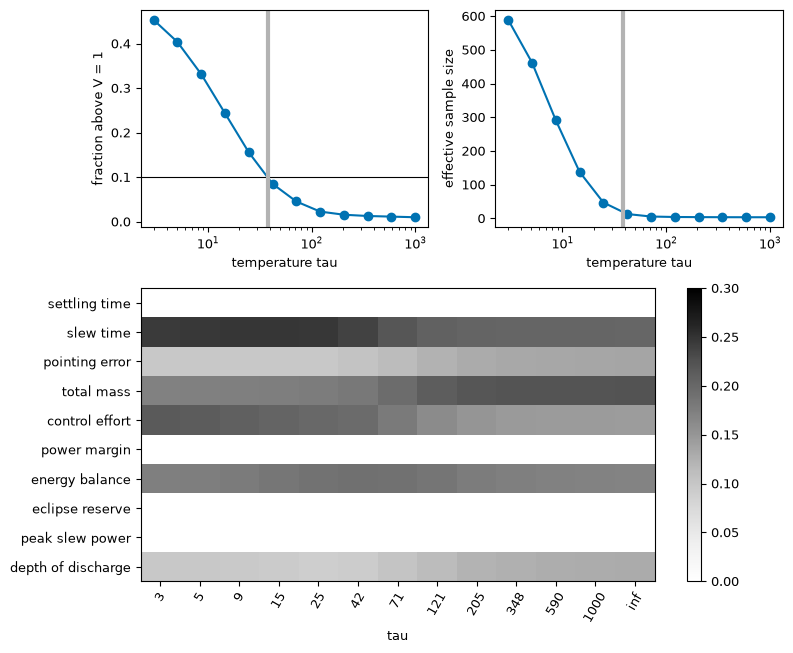

In [13]:
case.tau_sweep_figure(study, fit)

:::{figure} #fig-tau-sweep
:label: fig-tau
The K = 1 fit across temperatures on the primary regime. Top left: the fraction of designs above V = 1 against the temperature tau, with the target fraction as a horizontal line. Top right: the effective sample size. Bottom: the exponent of each metric. The vertical bar marks the temperature selected. [enlarge](figures/fig-tau-sweep.png)
:::

In [14]:
from generate_findings import temperature_sentence

temperature_sentence(study, fit)

'The selected temperature is tau = 38.1: a fraction 0.096 of designs lies above V = 1 (the target is 0.10), the band 1/tau is 0.0262 and the effective sample size is 16 designs.'

In [15]:
from generate_findings import planted_sentence

planted_sentence()

'The planted table has 900 rows, 4 metrics and 3 planted facets.'

{numref}`Figure %s <fig-tau>` shows how the temperature is selected. Where the answer must be known, we plant it: a synthetic table with three facets of known exponents ({ref}`Appendix C <appendix-c>` gives its generator), from which {numref}`Section %s <sect-case-analysis>` asks whether the fit recovers them.

(sect-case-analysis)=
## Case analysis

We read the case as the method asks: what contends, how, and where designs sit (tables: {ref}`Appendix D <appendix-d>`; digits that hold: {ref}`D.11 <sub-d-11>`).

In [16]:
from generate_findings import recovery_sentence

recovery_sentence()

'**A known answer.** On 20 planted tables (400 rows, 4 metrics) the fit recovers all three facets to within 0.05 in 16, at the exact maximum and at temperature 50; the 4 failures have 5, 5, 6 and 11 frontier rows on their thinnest facet (<a href="supporting-material/#sub-d-14" target="_self" style="color:inherit;text-decoration:underline">Appendix D.14</a>).'

**One facet.** At K = 1 the fit reports one tension at the balanced point ({numref}`Figure %s <fig-plane-1>`).

In [17]:
fit3 = fits[3]
band = fit.band  # the K = 1 band at every K (gap G-9)

In [18]:
from generate_findings import k1_sentence

k1_sentence(study, fit)

'At K = 1 the exact-maximum fit has a 6-lemma across controls, power and energy, plus mass: total mass, slew time, energy balance, control effort, pointing error and depth of discharge contend, with working-temperature exponents from 0.09 to 0.24.'

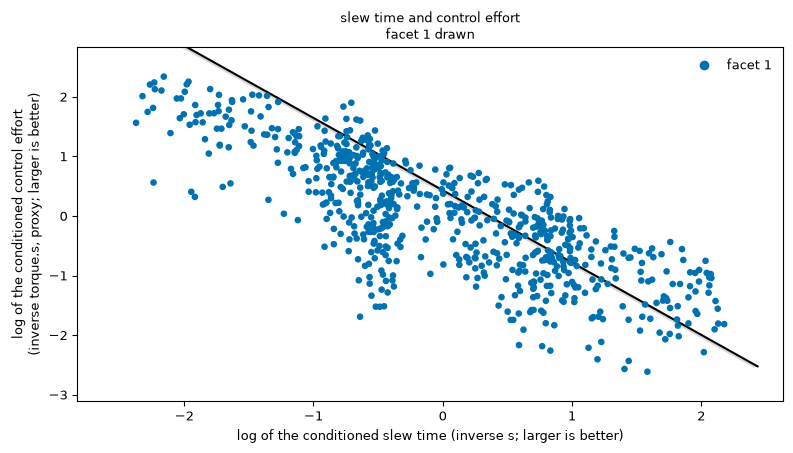

In [19]:
case.log_plane_figure(study, fit)

:::{figure} #fig-plane-k1
:label: fig-plane-1
Log-metric planes of the K = 1 fit (primary regime), one per pair of the facet's largest exponents, with the near-frontier band. [enlarge](figures/fig-plane-k1.png)
:::

**Three facets.** At K = 3 the tension separates into three facets with different contending sets: {numref}`Figure %s <fig-plane-3>` shows their envelope, {numref}`Figure %s <fig-chart-3>` places each design and {numref}`Figure %s <fig-tensions-3>` shows what trades off.

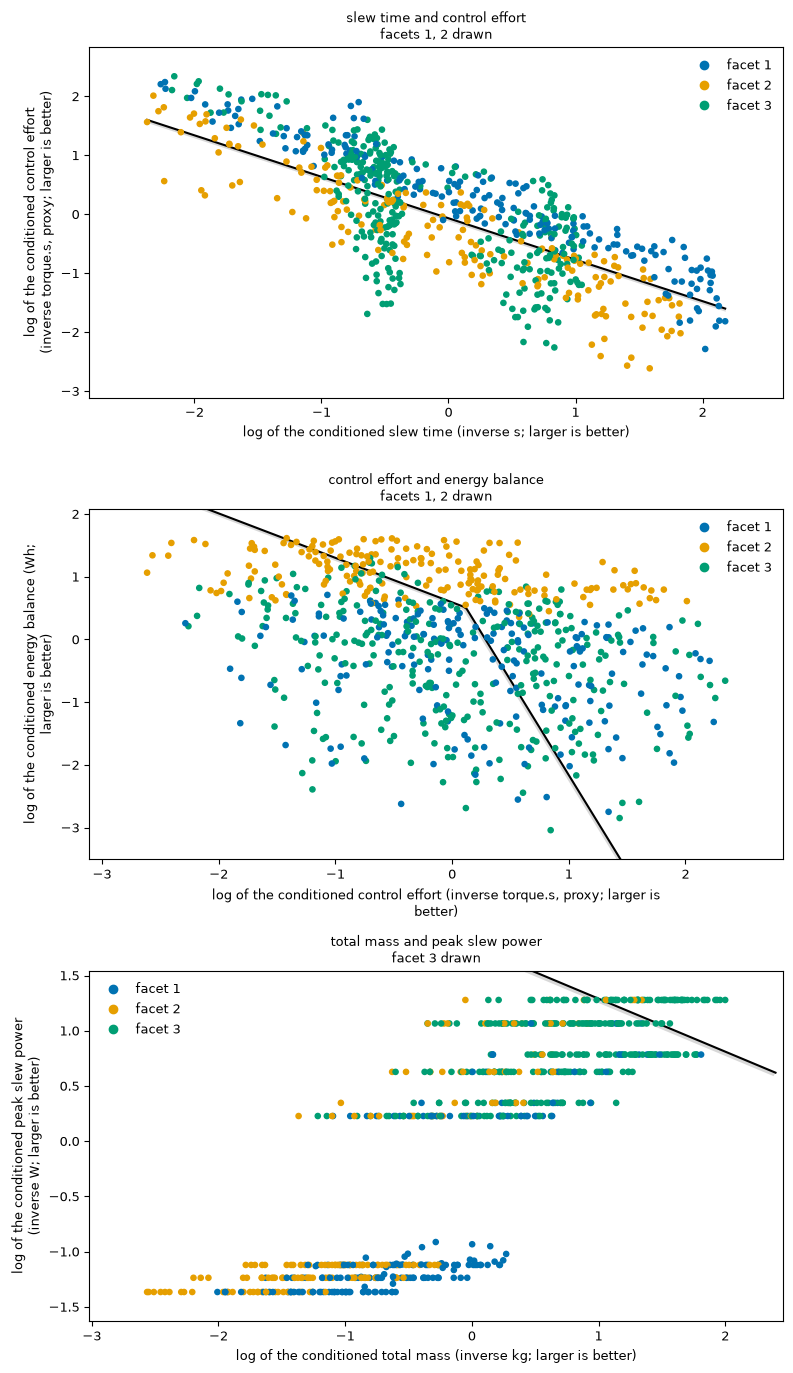

In [20]:
case.log_plane_figure(study, fit3, band=band)

:::{figure} #fig-plane-k3
:label: fig-plane-3
Log-metric planes of the K = 3 fit with the near-frontier band; designs coloured by facet, lines the facets. [enlarge](figures/fig-plane-k3.png)
:::

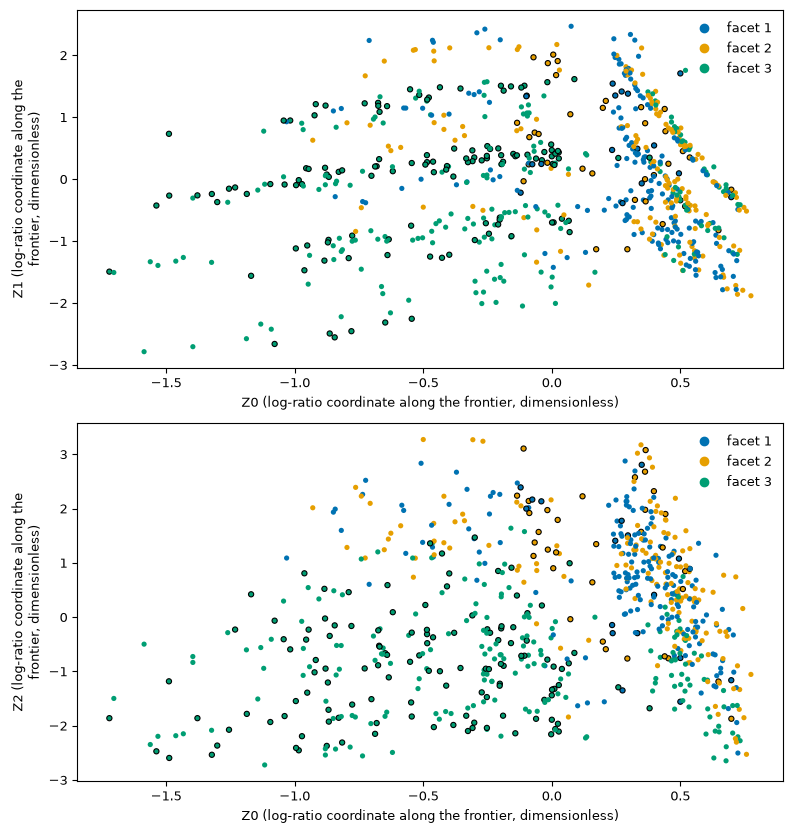

In [21]:
case.coordinates_figure(study, fit3, band=band)

:::{figure} #fig-chart-k3
:label: fig-chart-3
The chart of the K = 3 fit: the first three position coordinates, coloured by facet, near-frontier designs outlined. [enlarge](figures/fig-chart-k3.png)
:::

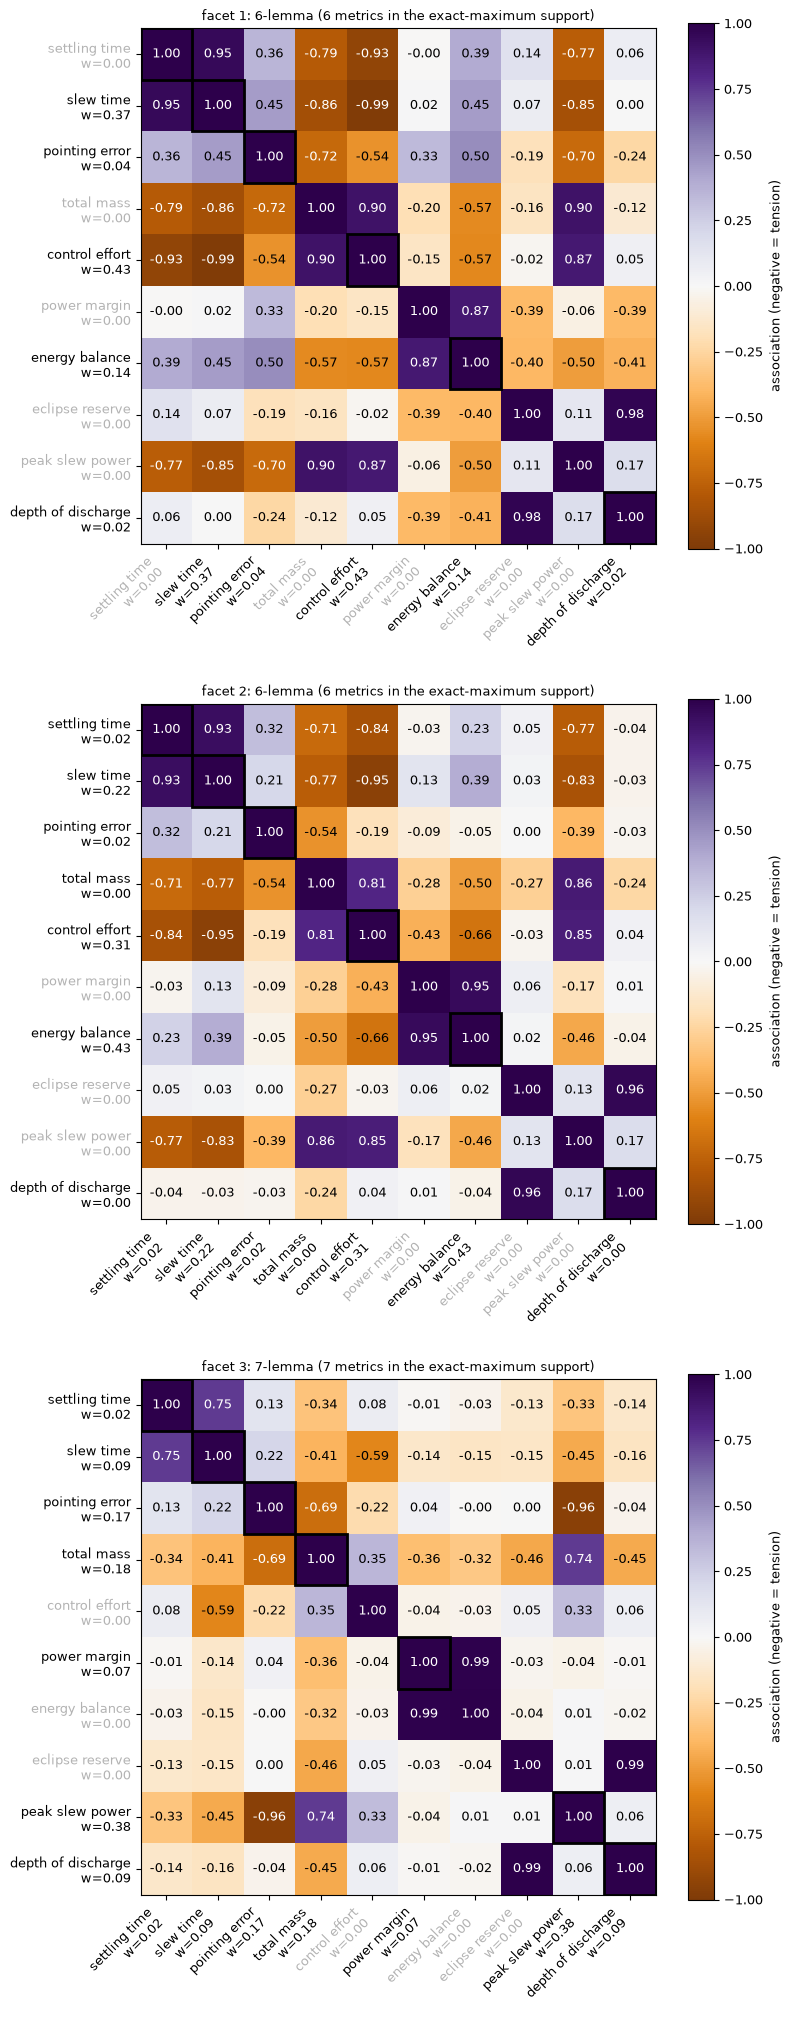

In [22]:
case.tension_figure(study, fit3, band=band)

:::{figure} #fig-tensions-k3
:label: fig-tensions-3
Association among the near-frontier designs of each K = 3 facet (negative: tension). Outlined: the contending set, the support of the exact-maximum fit; w is the fitted exponent, small for some members. [enlarge](figures/fig-tensions-k3.png)
:::

In [23]:
from generate_findings import k_sweep_sentence

k_sweep_sentence(study, fits)

'The mean slack falls from 0.20 at K = 1 to 0.138 at K = 2 and 0.117 at K = 3, at the temperatures 38, 113 and 195; refitted at the K = 1 temperature it falls to 0.09 and 0.05 (<a href="supporting-material/#sub-d-15" target="_self" style="color:inherit;text-decoration:underline">Appendix D.15</a>). The K = 3 facets have contending sets (exact-maximum supports) of 6, 6 and 7 metrics; peak slew power, power margin and settling time are absent from the K = 1 set.'

Mean slack falls with K by construction and cannot choose it: three facets is the analyst's choice; the finding: their sets differ.

**Two regimes.** The same pipeline on the baseline regime separates the problem's contribution from the gains' ({numref}`Figure %s <fig-regimes-1>`).

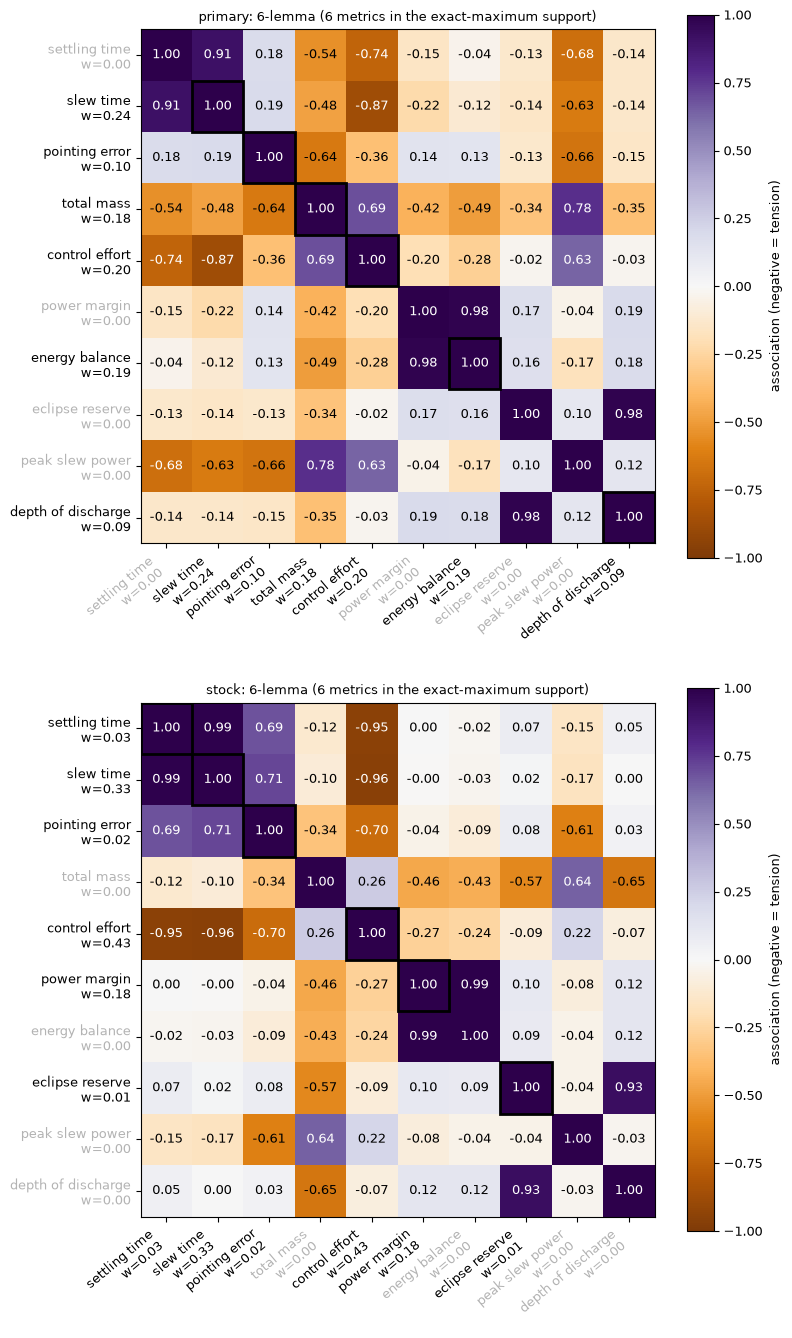

In [24]:
case.regime_figure()

:::{figure} #fig-regimes
:label: fig-regimes-1
The two regimes: association among near-frontier designs at K = 1, primary above, stock below; outlined: the contending set. [enlarge](figures/fig-regimes.png)
:::

In [25]:
from generate_findings import regime_sentence

regime_sentence()

'The regimes return a 6-lemma and a 6-lemma sharing 3 metrics (control effort, pointing error and slew time); the primary regime alone has depth of discharge, energy balance and total mass, the stock regime alone eclipse reserve, power margin and settling time. The stock set spans controls plus power and energy: mass enters only in the primary regime.'

**Candidates.** Candidates are scored against the K = 1 fit ({ref}`Appendix D.7 <sub-d-7>`).

In [26]:
cand = case.candidate_table(study, fit)

In [27]:
from generate_findings import candidates_sentence

candidates_sentence(cand)

'The 3 measured candidates have lowest energy differential -0.144 and highest -0.072 to -0.071, and 0 of them lie beyond the fitted reference surface.'

**Propose, predict, check.** A regressor from configuration to chart coordinates predicts where proposals fall ({numref}`Figure %s <fig-predict-check-1>`); we then measure them.

In [28]:
reg = case.fit_regressor(study)

In [29]:
pc = case.predict_check(study, reg)

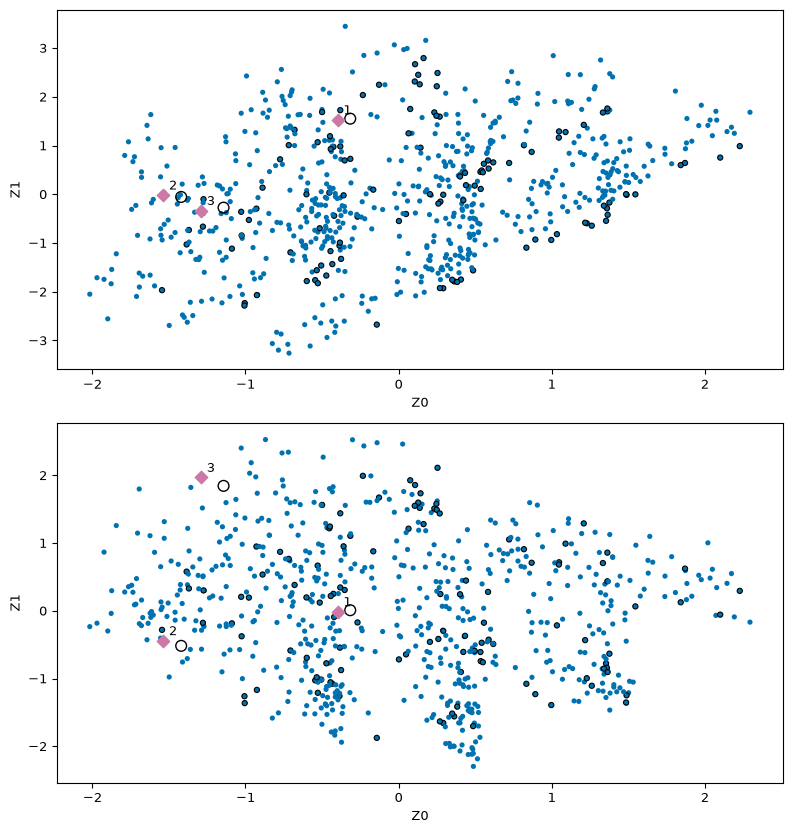

In [30]:
case.predict_check_figure(study, reg)

:::{figure} #fig-predict-check
:label: fig-predict-check-1
Predicted (open circles) and measured (diamonds) chart position of each proposed design. [enlarge](figures/fig-predict-check.png)
:::

In [31]:
from generate_findings import predict_check_sentence

predict_check_sentence(pc, reg)

"Of 3 proposals, the predicted energy differential lies within the regressor's own band 1/tau = 0.0651 of the measured one for 3, and the predicted position within that band for 0; position errors run from 1.4 to 3.1 bands."

(sect-discussion)=
## Discussion

**Interpretation is human validation.** The fit reports what contends; whether that is an explicable trade-off is for an engineer to decide. The exponents and exchange rates are features of the conditioned empirical model: they describe how the sampled designs trade, and not a causal exchange that changing a variable would reproduce. A hole in the chart is an opportunity only where the trade space is log-convex around it, which the data cannot prove. Novelty $V-1$ says how far beyond the fitted reference surface a design lies, not whether anyone wants it.

**Verify and validate.** Machine verification shows that a formula follows from its hypotheses and that the code agrees; it does not show that the hypotheses suit a table. That is human validation, which remains for a human: the conditioning, the choice of K and the reading of every finding. {ref}`Appendix B <appendix-b>` gives one line of code to read each proof step against; it cannot say that a sentence means what its line computes.


In [32]:
from generate_findings import predict_reading

predict_reading(pc, reg)

'**What propose, predict, check showed.** It showed that the regressor places the energy differential of a proposal within its band (3 of 3), the easy part. It did not show that it places the position along the frontier (0 of 3), and 3 proposals illustrate and do not estimate a rate. A predicted crossing of V = 1 remains a hypothesis.'

**Why a frontier.** An answer far from the frontier is hard to justify, and the analysis must rerun on empirical data to support configuration management.

**Cross-application.** The input is a table of configurations and attributes. How the attributes were produced is a black box to the method, so the same functions serve a simulator, a physical test campaign or a human assessment. Another table runs through the same calls.

**Limits, in brief.** The fitted surface is a log-convex envelope. One facet is tangent at one place and is conservative off it. The exponents depend on the conditioning. Small samples determine exponents weakly. {ref}`Appendix E <appendix-e>` gives the ledger.

**PCA, what the contrast does and does not claim.** K = 1 finds one tension; several regional tensions need K > 1. A deflation-style search for successive tensions, as PCA extracts components, is a research question: we claim neither that it works nor that tensions are orthogonal. Tensions the sampling never exercised cannot appear.

**Novelty and white space.** By {prf:ref}`thm-invariant`, a design with $V=v$ is a frontier design scaled by $v$, so $V-1$ is a relative improvement, meaningful relative to the band $1/\tau$.

**The kernel direction.** The research question is which kernel expansions remain generalized posynomials, so that the programs stay geometric programs and the guarantees and reading rules carry over. Nothing here is built.

(sect-reproducibility)=
## Reproducibility and your own case

Every figure, table and reported number comes from a call into a tested module; {ref}`Appendix F <appendix-f>` gives the pinned toolchain, the environment of record, the commands and one row per item. To run your own table, supply configurations, attributes and a conditioning rule, and use the same calls; the package documentation is the user's guide.

(sect-future)=
## Future work and final remark

Future work follows the assumptions we named. Beyond one facet, K > 1 is built; beyond hard assignment with smoothing on request, a nonsmooth search on the tangent cones of the ridges, whose generalized gradient is the convex hull of the active normals, should tolerate the kinks. Beyond the analyst's K, selection rules. Beyond small K, scalability and speed, and a global search or certificate for the alternation (Q1). Beyond log-affine conditioning, GGP-compatible kernels, the generalization the search motivates. Beyond continuous variables within a category, discrete design variables. Beyond a log-convex envelope, the detection of dents and holes. Beyond illustrative hardware values, datasheet values. The search of {numref}`Section %s <sect-search>` needs a convergence theorem, and Q2 to Q4 need their own conditions.

**Final remark.** A new capability or technology entering the design space could be given a novelty or impact score from how far above $V=1$ it is forecast to sit. We offer this as a hook for future exploration, not as a result.

(sect-process)=
## Acknowledgments and process

Work was done in supervisor-gated work packages: a written scope the author approved before execution, and a review afterwards. AI coding assistance (Claude Code, Anthropic) drafted code, derivation scripts and text inside those packages, in a process modelled on the harness described in [@zargham2026incose], whose deterministic checks and named human approver are the verification mechanism this paper inherits. The derivations are machine-checked. The author takes responsibility.

(sect-cited)=
## Works cited

```{bibliography}
```